# Historical topology optimization experiment in English

English translation of the 2019 notebook. Code operations and image attachments are preserved; comments, plot labels and prose are translated. Short clarifications identify historical limitations. Saved execution outputs are cleared to avoid presenting them as results of this translation. Text embedded in original images remains part of the archive.

The original notebook remains unchanged. This copy has not been executed: `libtopology`, `X.npz` and trained checkpoints are absent. For the runnable implementation, follow the repository README.


**Topology optimization** optimizes the distribution of material within a design domain under specified loads and constraints, including geometric, strength and stiffness requirements.

Reducing structural mass and increasing specific strength are major design objectives. They are closely related to finding suitable geometric parameters for a component.

The aim is to determine the best material distribution under the prescribed loads so that an objective is minimized or maximized while satisfying constraints. Unlike conventional parameter optimization, topology optimization describes the design through a material distribution over a fixed domain. The material layout, and therefore the shape, changes during optimization.

<math>\begin{align}
&\underset{x}{\operatorname{minimize}} & &F = F(\mathbf{u(\rho), \rho}) =  \int_{\Omega}  f(\mathbf{u(\rho), \rho}) \mathrm{d}V \\
&\operatorname{subject\;to} 
& &G_0(\rho) = \int_{\Omega} \rho \mathrm{d}V - V_0 \leq 0 \\
&&&G_j(\mathbf{u}(\rho), \rho) \leq 0 \text{ with } j = 1, ..., m
\end{align}</math>

A topology optimization problem includes:

- An objective $F(\mathbf{u}(\rho),\rho)$. A common objective is minimum structural compliance, related to strain energy under fixed loads.
- A design variable: the pseudo-density vector $\rho$, indicating the presence or absence of material in each element. In a binary description, 1 means material and 0 means void. The state field $\mathbf{u}$ satisfies a linear or nonlinear governing equation.
- A design domain $\Omega$, defining where material may exist. Components or regions that must remain unchanged are treated as non-design regions.
- Constraints $G_j(\mathbf{u}(\rho),\rho)\leq0$, for $j=1,\ldots,m$, such as a material-volume limit or maximum stress.

Evaluating $\mathbf{u}(\rho)$ generally requires solving differential equations. The finite element method is commonly used because analytical solutions are usually unavailable.

The main methods considered here are **SIMP** (Solid Isotropic Material with Penalization), **ESO** (Evolutionary Structural Optimization), **level-set methods**, and combinations of these approaches.

**ESO** evaluates the stress distribution using finite element analysis. Low stress or strain can indicate inefficient use of material. The approach removes underutilized material by eliminating elements from the finite element model.

The historical motivation is to use material efficiently while keeping stresses within acceptable limits.

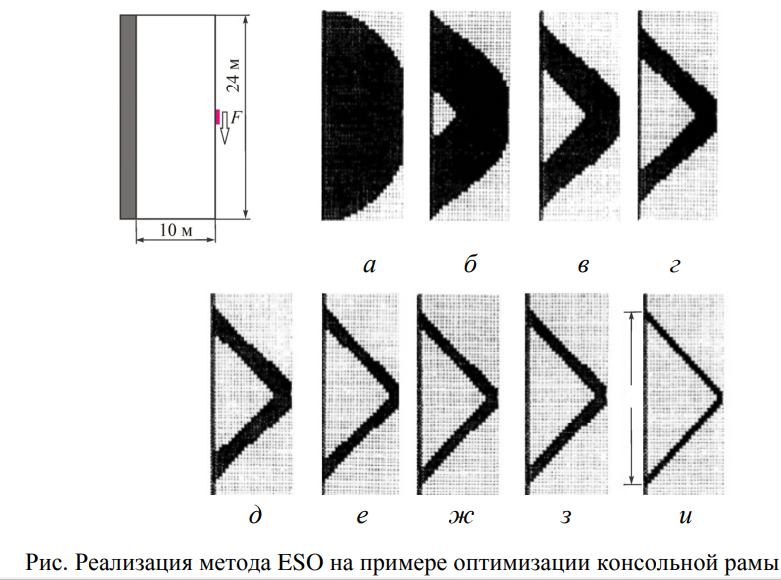

**SIMP (Solid Isotropic Material with Penalization)** introduces a virtual density field to represent material distribution. It redistributes material to reduce compliance under specified boundary conditions. Additive manufacturing can help realize complex resulting layouts.

The original text associated this with a uniformly strong structure; minimum compliance alone does not guarantee uniform stress or strength.

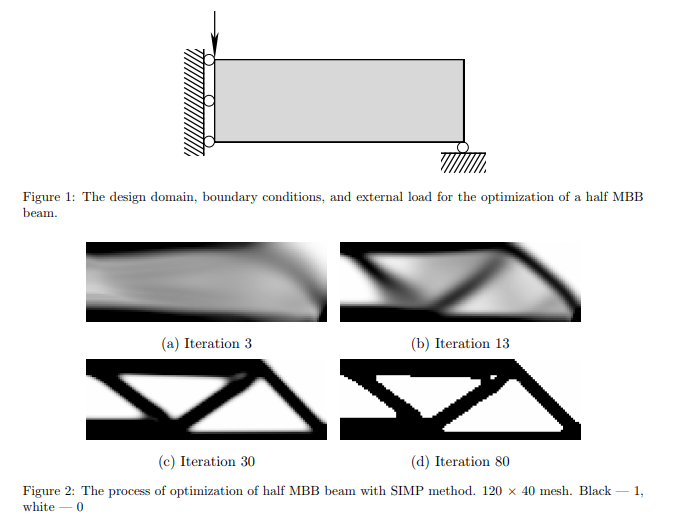

A **level-set method** represents a curve or surface implicitly as the zero level of a higher-dimensional function. Changes to that function evolve the boundary. In structural topology optimization, boundaries can evolve to minimize elastic strain energy.

**The historical aim of this work** was to apply deep learning to computationally expensive parts of conventional topology optimization and investigate faster prediction and generalization.

The proposed tasks were:

- Generate a dataset using a topology optimization method.
- Select a neural-network architecture.
- Choose parameters and train the network.
- Evaluate the resulting model.

The original aspiration of general scalability was a research goal, not an established result.

## Dataset generation

The experiment records 50 iterations for each randomly generated problem. Early iterations, approximately iterations 3–5, are used to predict the material layout at iteration 50.

The test problem is a square plate with one edge clamped and a 1 N load applied at the opposite side. Varying the load position generates cases. The plate is discretized into 1024 elements (32×32) for finite element analysis.

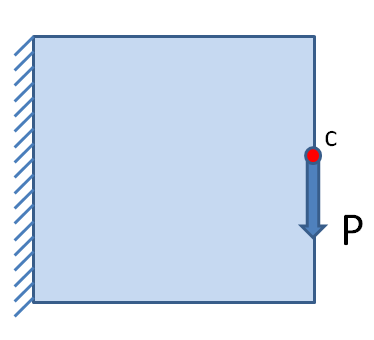

A custom library, *libtopology*, was used to generate training trajectories and the target topology at iteration 50:

```python
import libtopology as tp
X_ds = []
Y_ds = []
for i in range(2, 34, 2):
    nelx = 32  # Number of elements in the horizontal direction
    nely = 32  # Number of elements in the vertical direction
    volfrac = 0.5  # Final material volume / design-domain volume
    penal = 3  # Penalization exponent
    rmin = 1.5  # Filter radius in element units
    iterat = 50
    crdX = i
    for k in range(16, 67):
        crdY = k
        X, Y = tp.top(nelx, nely, volfrac, penal, rmin, crdX, crdY, iterat)
        X_ds.append(X)
        Y_ds.append(Y)
np.savez('X', np.array(X_ds), np.array(Y_ds))
```

At each step, *libtopology* performs finite element analysis, evaluates density updates against optimality criteria and updates the material layout. The library and generated dataset are not included in this repository.

Load the generated dataset and identify the training trajectories and target designs.

In [ ]:
import time
from time import time
import random
import pylab as py
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from skimage.transform import resize

In [ ]:
#!tensorboard --logdir=logs

In [ ]:
data = np.load('./X.npz')
data.files

In [ ]:
train = data['arr_0']
target = data['arr_1']
print(train.shape, target.shape)

plt.figure(figsize=(10, 8))
plt.subplot(1,3,1)
plt.title('Iteration 3')
py.imshow(train[8][2,:,:], cmap = py.cm.gray)

plt.subplot(1,3,2)
plt.title('Iteration 5')
py.imshow(train[8][4,:,:], cmap = py.cm.gray)

plt.subplot(1,3,3)
plt.title('Iteration 50')
py.imshow(target[8][0,:,:], cmap = py.cm.gray)
py.show()

In [ ]:
# Swap axes 1 and 3 for subsequent processing
train = train.swapaxes(1,3)
target = target.swapaxes(1,3)
target.shape, train.shape

The historical experiment manually augments the data with rotations of 90°, 180° and 270°. The original motivation was that arbitrary rotations require corresponding changes in the load direction and problem definition.

For a new experiment, transform density fields, loads and supports consistently, split cases before augmentation, and explicitly specify the spatial rotation axes. The historical code below is retained for inspection.

In [ ]:
train_res90 = np.rot90(train, 1, (1,2))
target90 = np.rot90(target, 1, (1,2))
train_res180 = np.rot90(train, 2)
target180 = np.rot90(target, 2)
train_res270 = np.rot90(train, 3, (1,2))
target270 = np.rot90(target, 3, (1,2))

train_fin = np.vstack((train, train_res90))
train_fin = np.vstack((train_fin, train_res180))
train_fin = np.vstack((train_fin, train_res270))

target_fin = np.vstack((target, target90))
target_fin = np.vstack((target_fin, target180))
target_fin = np.vstack((target_fin, target270))

train_fin.shape, target_fin.shape

Four input strategies are considered:

1. The density field at iteration 5.
2. Density fields described in the original text as iterations 2–5.
3. The difference between iterations 5 and 4.
4. Combinations of these inputs.

The historical `1:4` slice below actually selects three states, rather than four. The original labels are retained in the translated plot strings.

In [ ]:
train_5 = (train_fin[:,:,:,4]/(train_fin[:,:,:,4]).max()).reshape(3264,32,32,1)
train_2_5 = train_fin[:,:,:,1:4]/(train_fin[:,:,:,1:4]).max()
train_res = (abs(train_fin[:,:,:,4] - train_fin[:,:,:,3])/(abs(train_fin[:,:,:,4] - train_fin[:,:,:,3])).max()).reshape(3264,32,32,1)
target_fin = target_fin/target_fin.max()

Choose a threshold to create a mask from the final optimization state. Train models to predict either the final density field or its binary mask.

In [ ]:
thresh1 = target_fin.copy()
thresh1[thresh1 > target_fin.mean()*1.5] = 1
thresh1[thresh1 <= target_fin.mean()*1.5] = 0
py.imshow(np.squeeze(thresh1[1]))
plt.show()

Display the inputs for the first three strategies alongside the target topology.

In [ ]:
ix = random.randint(0, len(target_fin)-1)
print(ix)

plt.figure(figsize=(16, 12))
plt.subplot(1,4,1)
plt.title('Iteration 5')
py.imshow(np.squeeze(train_5[ix]))

plt.subplot(1,4,2)
plt.title('Iterations 2-5')
py.imshow(np.squeeze(train_2_5[ix]))

plt.subplot(1,4,3)
plt.title('Difference between iterations 5 and 4')
py.imshow(np.squeeze(train_res[ix]))

plt.subplot(1,4,4)
plt.title('Iteration 50')
py.imshow(np.squeeze(thresh1[ix]), cmap='pink')
py.imshow(np.squeeze(target_fin[ix]), alpha=0.5)
plt.show()

Two tasks are considered: predicting a binary mask as image segmentation, and predicting a continuous density field.

For segmentation, use Intersection over Union (IoU), also called the Jaccard coefficient, and a mean-IoU variant:

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}.$$

For density prediction, use mean squared error:

$$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^n(Y_i-\hat Y_i)^2.$$

The historical notebook also proposes the coefficient of determination and digital image correlation:

$$R^2=1-\frac{SS_{res}}{SS_{tot}}.$$

Digital image correlation compares centered reference and deformed image intensities using normalized correlation. The `r2` and `dic` functions below do not correctly implement the intended definitions and are retained as historical code. These image metrics do not replace structural reanalysis.

In [ ]:
# IoU metric 
def iou(y_true, y_pred):
    smooth = 1e-12
    intersection = K.sum(y_true * y_pred, axis=[0, -1, -2])
    sum_ = K.sum(y_true + y_pred, axis=[0, -1, -2])
    jac = (intersection + smooth) / (sum_ - intersection + smooth)
    return K.mean(jac)

# Mean IoU metric
def mean_iou(y_true, y_pred):
    prec = []
    for t in np.arange(0, 1, 0.1):
        y_pred_ = tf.to_int32(y_pred > t)
        score, up_opt = tf.metrics.mean_iou(y_true, y_pred_, 2)
        K.get_session().run(tf.local_variables_initializer())
        with tf.control_dependencies([up_opt]):
            score = tf.identity(score)
        prec.append(score)
    return K.mean(K.stack(prec), axis=0)

def r2(y_true, y_pred):
    numerator = K.sum(y_true - y_pred, axis=[0, -1, -2])
    denominator = K.sum(y_true + K.mean(y_true), axis=[0, -1, -2])
    r2 = 1 - (numerator**2 / denominator**2)
    return K.mean(r2)

def dic(y_true, y_pred):
    numerator = K.sum(y_true - K.mean(y_true), axis=[0, -1, -2])*K.sum(y_pred - K.mean(y_pred), axis=[0, -1, -2])
    denominator = K.sum(y_true - K.mean(y_true), axis=[0, -1, -2])**2 * K.sum(y_pred - K.mean(y_pred), axis=[0, -1, -2])**2
    dic = 1 - (numerator / denominator**0.5)
    return K.mean(dic)

def mse(y_true, y_pred):
    mse = tf.keras.metrics.mean_squared_error(y_true, y_pred)
    return K.mean(mse)



The experiment uses **U-Net**, a convolutional neural network introduced in 2015 for biomedical image segmentation at the University of Freiburg. See [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597).

The architecture is fully convolutional and uses a contracting path and an expanding path, forming the characteristic U shape. In the original architecture, each contracting stage uses two 3×3 convolutions with ReLU and a 2×2 max-pooling operation with stride 2, while increasing the feature-channel count.

Each expanding stage upsamples the feature map, reduces the channel count with a 2×2 convolution, concatenates the corresponding contracting-path features, and applies two 3×3 convolutions with ReLU. Cropping aligns the feature maps when unpadded convolutions remove boundary pixels. A final 1×1 convolution maps features to the required output classes.

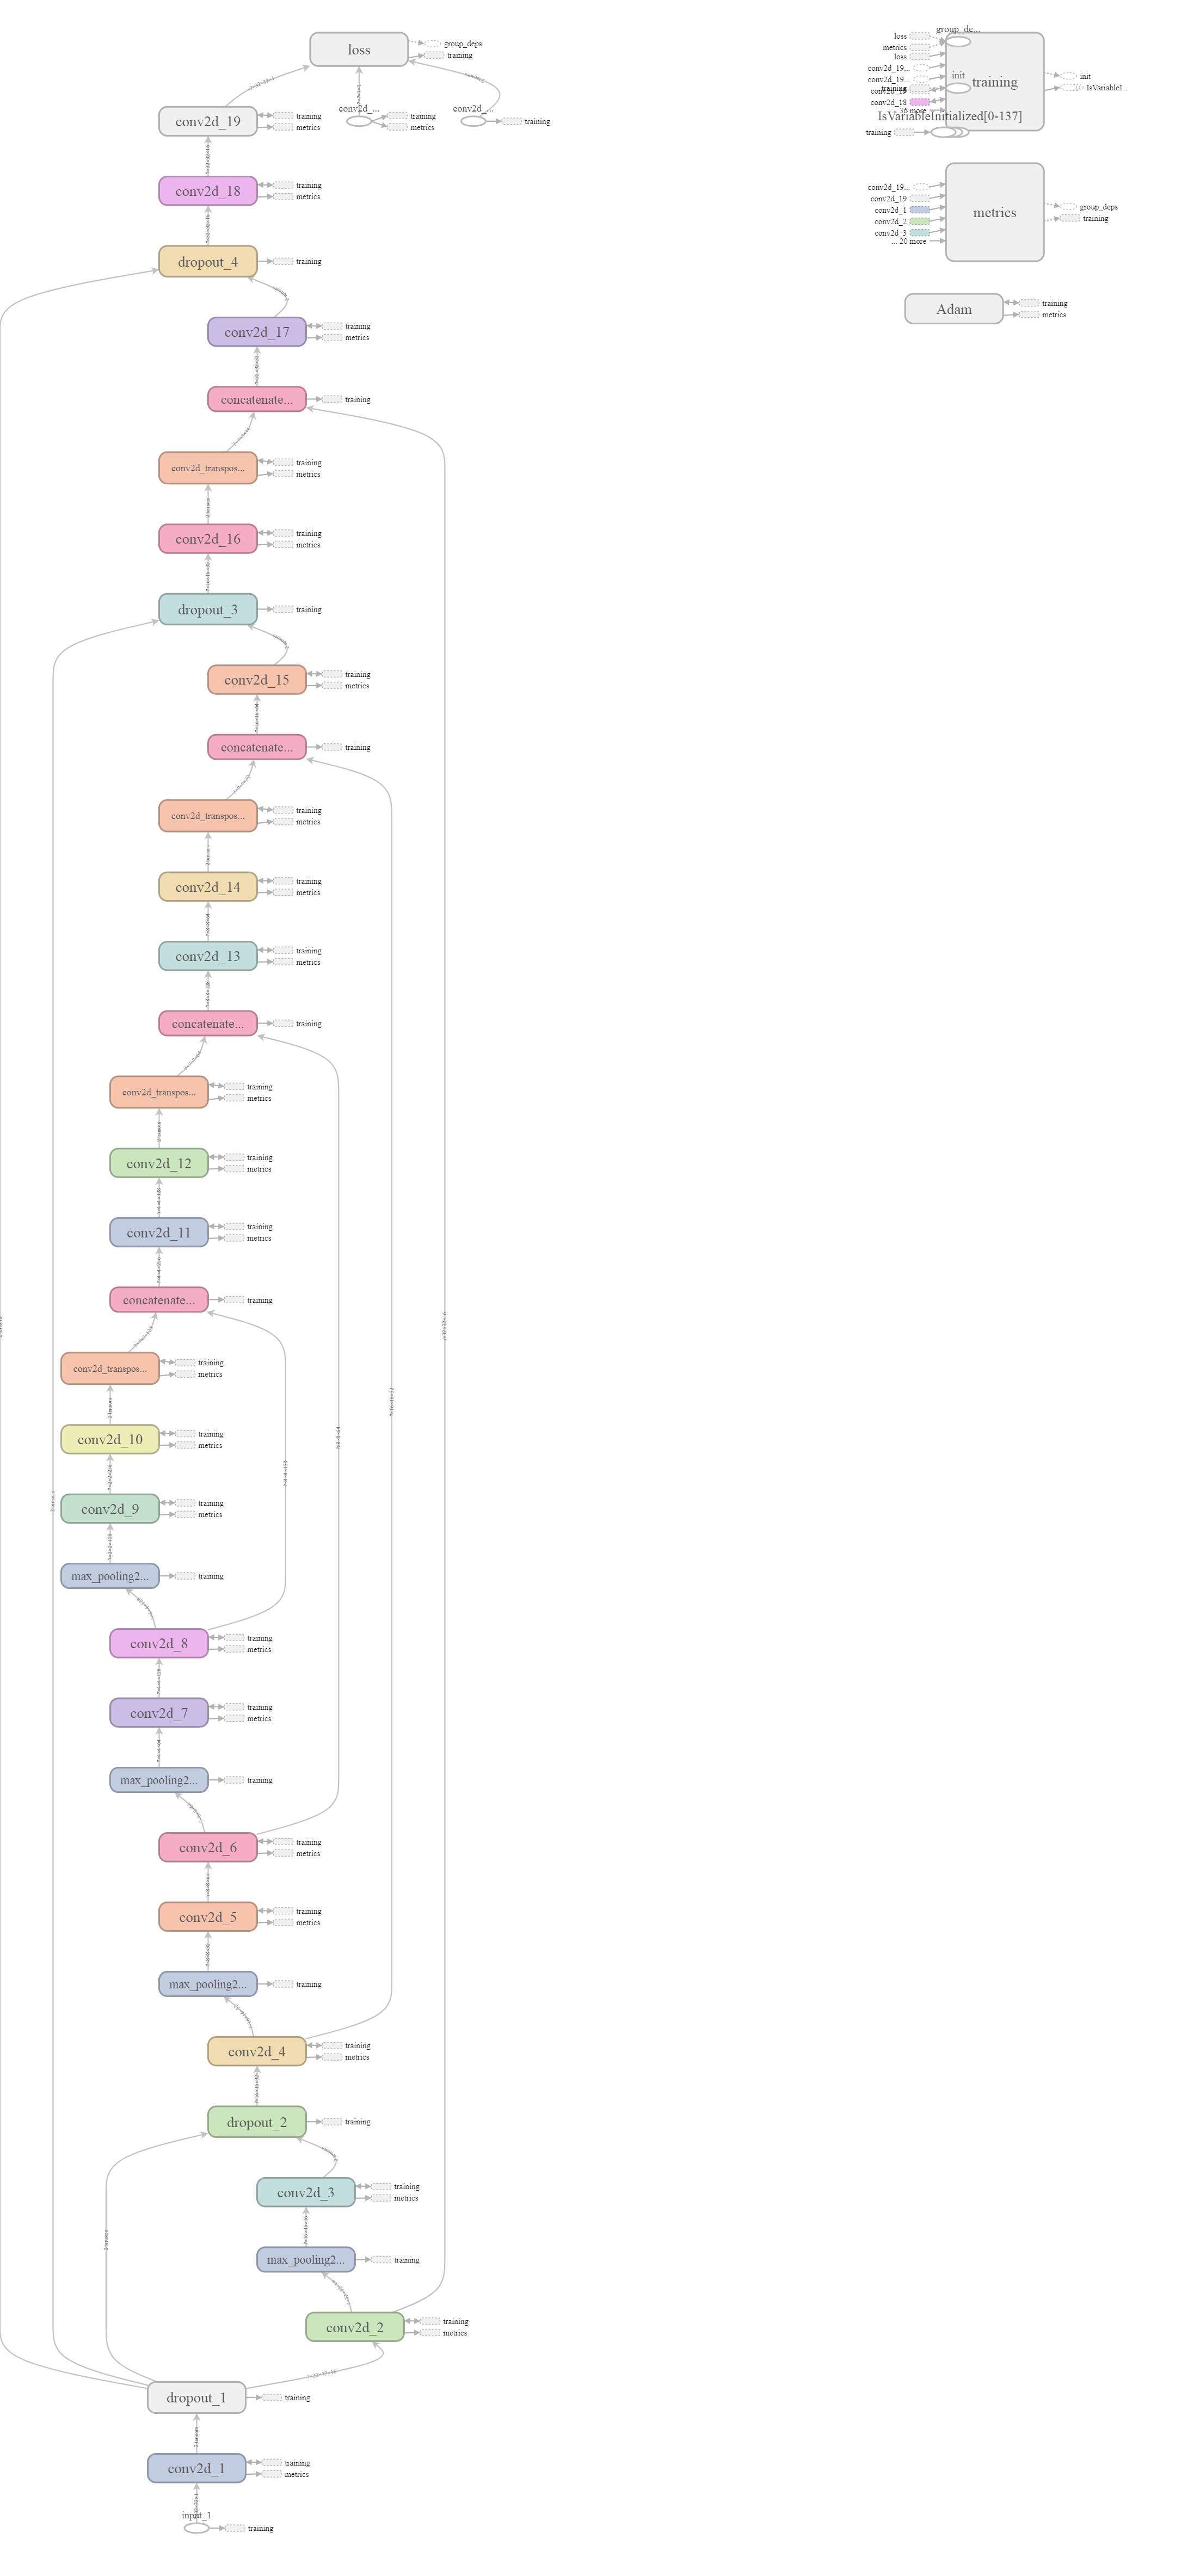

In [ ]:
# Import the required libraries
import keras
from keras import backend as K
from keras.preprocessing.image import ImageDataGenerator
from keras.models import Sequential, load_model, Model
from keras.layers import Dense, Dropout, Flatten, BatchNormalization, Input, Lambda, normalization
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose, concatenate, UpSampling2D
from keras.callbacks import EarlyStopping, ModelCheckpoint, TensorBoard
from keras.optimizers import Adam
from keras.utils import np_utils

import tensorflow as tf

from sklearn.model_selection import train_test_split

from segmentation_models.losses import bce_jaccard_loss
from segmentation_models.metrics import iou_score

In [ ]:
train_x, test_x, train_y, test_y = train_test_split(train_5, target_fin, test_size=1/8.2, random_state=3017)
train_x.shape, test_x.shape

Function for constructing the U-Net model.

In [ ]:
def u_net(z=1):
    inputs = Input((32, 32, z))
    #s = Lambda(lambda x: x / 255) (inputs)
    #norm = BatchNormalization() (s)
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (inputs)
    c1 = Dropout(0.2) (c1)
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c1)
    p1 = MaxPooling2D((2, 2)) (c1)

    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (p1)
    c2 = Dropout(0.2) (c2)
    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c2)
    p2 = MaxPooling2D((2, 2)) (c2)

    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (p2)
    #c3 = Dropout(0.2) (c3)
    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c3)
    p3 = MaxPooling2D((2, 2)) (c3)

    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (p3)
    #c4 = Dropout(0.2) (c4)
    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c4)
    p4 = MaxPooling2D(pool_size=(2, 2)) (c4)

    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (p4)
    #c5 = Dropout(0.3) (c5)
    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c5)

    u6 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same') (c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (u6)
    #c6 = Dropout(0.2) (c6)
    c6 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c6)

    u7 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same') (c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (u7)
    #c7 = Dropout(0.2) (c7)
    c7 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c7)

    u8 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same') (c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (u8)
    c8 = Dropout(0.2) (c8)
    c8 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c8)

    u9 = Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same') (c8)
    u9 = concatenate([u9, c1], axis=3)
    c9 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (u9)
    c9 = Dropout(0.2) (c9)
    c9 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same') (c9)

    outputs = Conv2D(1, (1, 1), activation='sigmoid') (c9)

    model = Model(inputs=[inputs], outputs=[outputs])
    model.compile(optimizer='adam', loss=bce_jaccard_loss, metrics=[iou_score, mean_iou, mse])
    model.summary()
    
    return model

Train three networks to predict the density field at iteration 50. The first strategy uses the field at iteration 5 as input.

In [ ]:
model1 = u_net()
tensorboard = TensorBoard(log_dir='logs/{}'.format(time()))
earlystopper = EarlyStopping(patience=5, verbose=1)
checkpointer = ModelCheckpoint('model1_segm.h5', verbose=1, save_best_only=True)
results = model1.fit(train_x, train_y, validation_split=0.1, batch_size=64, epochs=100, 
                    callbacks=[earlystopper, checkpointer, tensorboard])

In [ ]:
print('Test-set metrics: ', model1.evaluate(test_x, test_y))

print(results.history.keys())
# Plot the metric history
plt.plot(results.history['mean_iou'])
plt.plot(results.history['val_mean_iou'])
plt.title('model1 mean_iou')
plt.ylabel('IoU')
plt.xlabel('epoch')
plt.legend(['mean_iou', 'val_mean_iou'], loc='upper left')
plt.show()

# Plot the Jaccard-score history
plt.plot(results.history['iou_score'])
plt.plot(results.history['val_iou_score'])
plt.title('model1 iou_score')
plt.ylabel('iou_score')
plt.xlabel('epoch')
plt.legend(['iou_score', 'val_iou_score'], loc='upper left')
plt.show()

# Plot the mean-squared-error history
plt.plot(results.history['mse'])
plt.plot(results.history['val_mse'])
plt.title('model1 mse')
plt.ylabel('mse')
plt.xlabel('epoch')
plt.legend(['mse', 'val_mse'], loc='upper left')
plt.show()

# Plot the loss history
plt.plot(results.history['loss'])
plt.plot(results.history['val_loss'])
plt.title('model1 loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()

In [ ]:
# Predictions on training, validation and test data
#model1 = load_model('model1_segm.h5', custom_objects={'mean_iou': mean_iou, 'iou': iou})
preds_test = model1.predict(test_x, verbose=1)

# # Threshold the predictions
# preds_test_t = (preds_test > 1).astype(np.uint8)

# Inspect a randomly selected example
ix = random.randint(0, len(preds_test)-1)
print(ix)
py.imshow(np.squeeze(test_y[ix]))
plt.show()
py.imshow(np.squeeze(preds_test[ix]))
plt.show()

The second strategy uses the early-iteration fields described historically as iterations 2–5. See the slice clarification above.

In [ ]:
train_x, test_x, train_y, test_y = train_test_split(train_2_5, target_fin, test_size=1/8.2, random_state=3017)

model2 = u_net(z=3)
 
tensorboard = TensorBoard(log_dir='logs/{}'.format(time()))
earlystopper = EarlyStopping(patience=5, verbose=1)
checkpointer = ModelCheckpoint('model2_segm.h5', verbose=1, save_best_only=True)
results = model2.fit(train_x, train_y, validation_split=0.1, batch_size=64, epochs=100, 
                    callbacks=[earlystopper, checkpointer, tensorboard])

In [ ]:
print('Test-set metrics', model2.evaluate(test_x, test_y))

print(results.history.keys())
# Plot the metric history
plt.plot(results.history['mean_iou'])
plt.plot(results.history['val_mean_iou'])
plt.title('model2 mean_iou')
plt.ylabel('IoU')
plt.xlabel('epoch')
plt.legend(['mean_iou', 'val_mean_iou'], loc='upper left')
plt.show()

# Plot the Jaccard-score history
plt.plot(results.history['iou_score'])
plt.plot(results.history['val_iou_score'])
plt.title('model2 iou_score')
plt.ylabel('iou_score')
plt.xlabel('epoch')
plt.legend(['iou_score', 'val_iou_score'], loc='upper left')
plt.show()

# Plot the mean-squared-error history
plt.plot(results.history['mse'])
plt.plot(results.history['val_mse'])
plt.title('model2 mse')
plt.ylabel('mse')
plt.xlabel('epoch')
plt.legend(['mse', 'val_mse'], loc='upper left')
plt.show()

# Plot the loss history
plt.plot(results.history['loss'])
plt.plot(results.history['val_loss'])
plt.title('model2 loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()

In [ ]:
# Predictions on test data
#model1 = load_model('model2_segm.h5', custom_objects={'mean_iou': mean_iou, 'iou': iou})
preds_test = model2.predict(test_x, verbose=1)

# # Threshold the predictions
# preds_test_t = (preds_test > 1).astype(np.uint8)

# Inspect a randomly selected example
ix = random.randint(0, len(preds_test)-1)
print(ix)
py.imshow(np.squeeze(test_y[ix]))
plt.show()
py.imshow(np.squeeze(preds_test[ix]))
plt.show()

The third strategy uses the difference between iterations 5 and 4.

In [ ]:
train_x, test_x, train_y, test_y = train_test_split(train_res, target_fin, test_size=1/8.2, random_state=3017)

model3 = u_net()
 
tensorboard = TensorBoard(log_dir='logs/{}'.format(time()))
earlystopper = EarlyStopping(patience=5, verbose=1)
checkpointer = ModelCheckpoint('model3_segm.h5', verbose=1, save_best_only=True)
results = model3.fit(train_x, train_y, validation_split=0.1, batch_size=64, epochs=100, 
                    callbacks=[earlystopper, checkpointer, tensorboard])

In [ ]:
print('Test-set metrics', model3.evaluate(test_x, test_y))

print(results.history.keys())
# Plot the metric history
plt.plot(results.history['mean_iou'])
plt.plot(results.history['val_mean_iou'])
plt.title('model3 mean_iou')
plt.ylabel('IoU')
plt.xlabel('epoch')
plt.legend(['mean_iou', 'val_mean_iou'], loc='upper left')
plt.show()

# Plot the Jaccard-score history
plt.plot(results.history['iou_score'])
plt.plot(results.history['val_iou_score'])
plt.title('model3 iou_score')
plt.ylabel('iou_score')
plt.xlabel('epoch')
plt.legend(['iou_score', 'val_iou_score'], loc='upper left')
plt.show()

# Plot the mean-squared-error history
plt.plot(results.history['mse'])
plt.plot(results.history['val_mse'])
plt.title('model3 mse')
plt.ylabel('mse')
plt.xlabel('epoch')
plt.legend(['mse', 'val_mse'], loc='upper left')
plt.show()

# Plot the loss history
plt.plot(results.history['loss'])
plt.plot(results.history['val_loss'])
plt.title('model3 loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()

In [ ]:
# Predictions on test data
#model1 = load_model('model3_segm.h5', custom_objects={'mean_iou': mean_iou, 'iou': iou})
preds_test = model3.predict(test_x, verbose=1)

# # Threshold the predictions
# preds_test_t = (preds_test > 1).astype(np.uint8)

# Inspect a randomly selected example
ix = random.randint(0, len(preds_test)-1)
print(ix)
py.imshow(np.squeeze(test_y[ix]))
plt.show()
py.imshow(np.squeeze(preds_test[ix]))
plt.show()

### Compare three strategies for predicting density fields

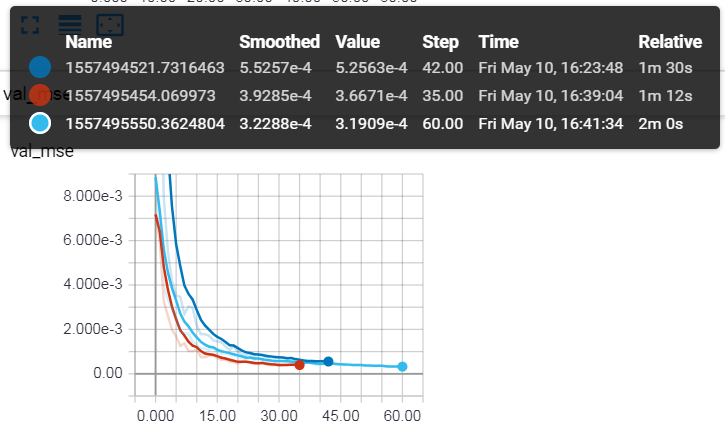

The historical validation-MSE plots suggested that the three-channel strategy (red curve) offered the best speed/quality tradeoff among these runs. This is an archived observation, not a newly reproduced benchmark.

### Image segmentation and mask prediction

In [ ]:
train_x, test_x, train_y, test_y = train_test_split(train_5, thresh1, test_size=1/8.2, random_state=3017)

model4 = u_net()
 
tensorboard = TensorBoard(log_dir='logs/{}'.format(time()))
earlystopper = EarlyStopping(patience=5, verbose=1)
checkpointer = ModelCheckpoint('model4_segm.h5', verbose=1, save_best_only=True)
results = model4.fit(train_x, train_y, validation_split=0.1, batch_size=64, epochs=100, 
                    callbacks=[earlystopper, checkpointer, tensorboard])

In [ ]:
print('Test-set metrics', model4.evaluate(test_x, test_y))

print(results.history.keys())
# Plot the metric history
plt.plot(results.history['mean_iou'])
plt.plot(results.history['val_mean_iou'])
plt.title('model4 mean_iou')
plt.ylabel('IoU')
plt.xlabel('epoch')
plt.legend(['mean_iou', 'val_mean_iou'], loc='upper left')
plt.show()

# Plot the Jaccard-score history
plt.plot(results.history['iou_score'])
plt.plot(results.history['val_iou_score'])
plt.title('model4 iou_score')
plt.ylabel('iou_score')
plt.xlabel('epoch')
plt.legend(['iou_score', 'val_iou_score'], loc='upper left')
plt.show()

# Plot the mean-squared-error history
plt.plot(results.history['mse'])
plt.plot(results.history['val_mse'])
plt.title('model4 mse')
plt.ylabel('mse')
plt.xlabel('epoch')
plt.legend(['mse', 'val_mse'], loc='upper left')
plt.show()

# Plot the loss history
plt.plot(results.history['loss'])
plt.plot(results.history['val_loss'])
plt.title('model4 loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()

In [ ]:
# Predictions on training, validation and test data
#model4 = load_model('model4_segm.h5', custom_objects={'mean_iou': mean_iou, 'iou': iou})
preds_test = model4.predict(test_x, verbose=1)

# # Threshold the predictions
# preds_test_t = (preds_test > 1).astype(np.uint8)

# Inspect a randomly selected example
ix = random.randint(0, len(preds_test)-1)
print(ix)
py.imshow(np.squeeze(test_y[ix]))
plt.show()
py.imshow(np.squeeze(preds_test[ix]))
plt.show()

Visualize convolutional-network filters.

In [ ]:
n=0
for layer in model4.layers:
    # Select convolutional layers
    n+=1
    if 'conv' not in layer.name:
        continue
    filters, biases = layer.get_weights()
    print(n, layer.name, filters.shape)

In [ ]:
# Get the convolutional-layer weights
filters, biases = model4.layers[10].get_weights()

In [ ]:
# Normalize filters to the range 0 to 1 for display
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

In [ ]:
# Display the first few filters as examples
n_filters, ix = 6, 1
for i in range(n_filters):
    # Get one filter
    f = filters[:, :, :, i]
    # Display filters in a grid
    for j in range(3):
        ax = py.subplot(n_filters, 3, ix)
        ax.set_xticks([])
        ax.set_yticks([])
        # Display in grayscale
        py.imshow(f[:, :, j], cmap='gray')
        ix += 1

py.show()

Inspect feature maps produced by selected convolutional-network layers.

In [ ]:
# Define a model that outputs selected intermediate layers
ixs = [2, 4, 6, 8, 10, 16, 19, 21, 26, 30]
outputs = [model4.layers[i+1].output for i in ixs]
model_ = Model(inputs=model4.inputs, outputs=outputs)
model_.summary()

# Select an image for analysis
img = test_x[18]
img = np.expand_dims(img, axis=0)
feature_maps = model_.predict(img)

In [ ]:
# Display results for each selected layer
square = 4
for fmap in feature_maps:
    ix = 1
    for _ in range(square):
        for _ in range(square):
            ax = py.subplot(square, square, ix)
            ax.set_xticks([])
            ax.set_yticks([])
            py.imshow(fmap[0, :, :, ix-1], cmap='RdBu')
            py.title(ix)
            ix += 1
    py.show()

# LinkNet

**LinkNet** is a lightweight deep architecture for semantic segmentation. Its initial block uses a 7×7 convolution with stride 2 followed by 2×2 max pooling with stride 2. The output stages restore the spatial resolution and reduce the feature-channel count.

For these small images, two encoder blocks and two decoder blocks are disabled in the historical implementation.

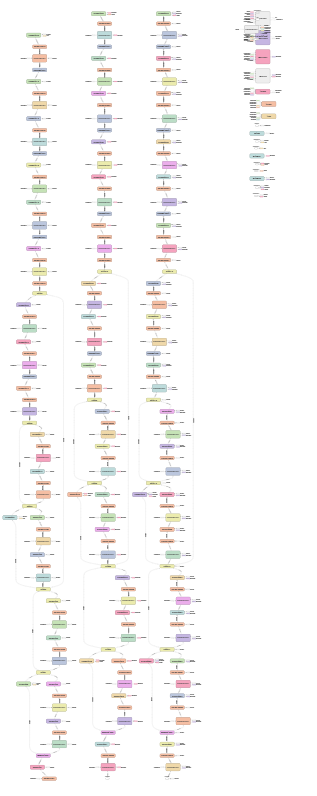

In [ ]:
from keras.layers import Input, concatenate, Conv2D, MaxPooling2D, Activation, UpSampling2D, BatchNormalization, add
from keras.layers.core import Flatten, Reshape
from keras.models import Model
from keras.regularizers import l2
import keras.backend as K

In [ ]:
def _shortcut(input, residual):
    
    input_shape = K.int_shape(input)
    residual_shape = K.int_shape(residual)
    stride_width = int(round(input_shape[1] / residual_shape[1]))
    stride_height = int(round(input_shape[2] / residual_shape[2]))
    equal_channels = input_shape[3] == residual_shape[3]

    shortcut = input
    if stride_width > 1 or stride_height > 1 or not equal_channels:
        shortcut = Conv2D(filters=residual_shape[3],
                          kernel_size=(1, 1),
                          strides=(stride_width, stride_height),
                          padding="valid",
                          kernel_initializer="he_normal",
                          kernel_regularizer=l2(0.0001))(input)

    return add([shortcut, residual])

def encoder_block(input_tensor, m, n):
    x = BatchNormalization()(input_tensor)
    x = Activation('relu')(x)
    x = Conv2D(filters=n, kernel_size=(3, 3), strides=(2, 2), padding="same")(x)

    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Conv2D(filters=n, kernel_size=(3, 3), padding="same")(x)

    added_1 = _shortcut(input_tensor, x)

    x = BatchNormalization()(added_1)
    x = Activation('relu')(x)
    x = Conv2D(filters=n, kernel_size=(3, 3), padding="same")(x)

    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Conv2D(filters=n, kernel_size=(3, 3), padding="same")(x)

    added_2 = _shortcut(added_1, x)

    return added_2

def decoder_block(input_tensor, m, n):
    x = BatchNormalization()(input_tensor)
    x = Activation('relu')(x)
    x = Conv2D(filters=int(m/4), kernel_size=(1, 1))(x)

    x = UpSampling2D((2, 2))(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Conv2D(filters=int(m/4), kernel_size=(3, 3), padding='same')(x)

    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Conv2D(filters=n, kernel_size=(1, 1))(x)

    return x

def LinkNet(input_shape=(32, 32, 1), classes=1):
    inputs = Input(shape=input_shape)

    x = BatchNormalization()(inputs)
    x = Activation('relu')(x)
    x = Conv2D(filters=64, kernel_size=(7, 7), strides=(2, 2))(x)

    x = MaxPooling2D((3, 3), strides=(2, 2), padding="same")(x)

    encoder_1 = encoder_block(input_tensor=x, m=64, n=64)

    encoder_2 = encoder_block(input_tensor=encoder_1, m=64, n=128)

#     encoder_3 = encoder_block(input_tensor=encoder_2, m=128, n=256)

#     encoder_4 = encoder_block(input_tensor=encoder_3, m=256, n=512)

# #     decoder_4 = decoder_block(input_tensor=encoder_4, m=512, n=256)

# #     decoder_3_in = add([decoder_4, encoder_3])
# #     decoder_3_in = Activation('relu')(decoder_3_in)

#     decoder_3 = decoder_block(input_tensor=encoder_4, m=256, n=128)

#     decoder_2_in = add([decoder_3, encoder_2])
#     decoder_2_in = Activation('relu')(decoder_2_in)

    decoder_2 = decoder_block(input_tensor=encoder_2, m=128, n=64)

    decoder_1_in = add([decoder_2, encoder_1])
    decoder_1_in = Activation('relu')(decoder_1_in)

    decoder_1 = decoder_block(input_tensor=decoder_1_in, m=64, n=64)

    x = UpSampling2D((2, 2))(decoder_1)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Conv2D(filters=32, kernel_size=(3, 3), padding="same")(x)

    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Conv2D(filters=32, kernel_size=(3, 3), padding="same")(x)

    x = UpSampling2D((2, 2))(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    # x = Conv2D(filters=classes, kernel_size=(2, 2), padding="same")(x)
    
    outputs = Conv2D(1, (1, 1), activation='sigmoid') (x)
    model = Model(inputs=inputs, outputs=outputs)

    return model

In [ ]:
train_x, test_x, train_y, test_y = train_test_split(train_5, thresh1, test_size=1/8.2, random_state=3017)

m = LinkNet()
m.compile(optimizer='adam', loss=bce_jaccard_loss, metrics=[iou_score, mean_iou, mse])
m.summary()

tensorboard = TensorBoard(log_dir='logs/{}'.format(time()))
earlystopper = EarlyStopping(patience=5, verbose=1)
checkpointer = ModelCheckpoint('model_segm_link.h5', verbose=1, save_best_only=True)

results = m.fit(train_x, train_y, validation_split=0.1, batch_size=64, epochs=100, 
                    callbacks=[earlystopper, checkpointer, tensorboard])

In [ ]:
print('Test-set metrics', m.evaluate(test_x, test_y))

print(results.history.keys())
# Plot the metric history
plt.plot(results.history['mean_iou'])
plt.plot(results.history['val_mean_iou'])
plt.title('model_LinkNet mean_iou')
plt.ylabel('IoU')
plt.xlabel('epoch')
plt.legend(['mean_iou', 'val_mean_iou'], loc='upper left')
plt.show()

# Plot the Jaccard-score history
plt.plot(results.history['iou_score'])
plt.plot(results.history['val_iou_score'])
plt.title('model_LinkNet iou_score')
plt.ylabel('iou_score')
plt.xlabel('epoch')
plt.legend(['iou_score', 'val_iou_score'], loc='upper left')
plt.show()

# Plot the mean-squared-error history
plt.plot(results.history['mse'])
plt.plot(results.history['val_mse'])
plt.title('model_LinkNet mse')
plt.ylabel('mse')
plt.xlabel('epoch')
plt.legend(['mse', 'val_mse'], loc='upper left')
plt.show()

# Plot the loss history
plt.plot(results.history['loss'])
plt.plot(results.history['val_loss'])
plt.title('model_LinkNet loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()

In [ ]:
# Predictions on training, validation and test data
#model1 = load_model('model_segm.h5', custom_objects={'mean_iou': mean_iou, 'iou': iou})
preds_test = m.predict(test_x, verbose=1)

# # Threshold the predictions
# preds_test_t = (preds_test > 1).astype(np.uint8)

# Inspect a randomly selected example
ix = random.randint(0, len(preds_test)-1)
print(ix)
py.imshow(np.squeeze(test_y[ix]))
plt.show()
py.imshow(np.squeeze(preds_test[ix]))
plt.show()

Compare segmentation results for **U-Net** (pink curve) and **LinkNet** (green curve).

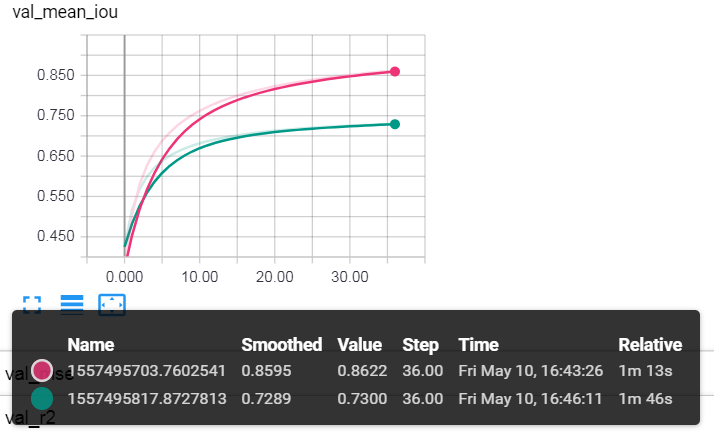

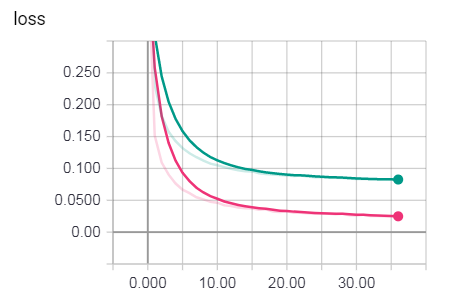


The historical plots report faster training for U-Net than for LinkNet and a higher metric value, approximately 0.86 versus 0.73.

The original interpretation was that deep learning might be applicable to topology prediction and that U-Net was preferable in this experiment. These archived image-metric scores are not verified structural-performance results and are affected by the historical evaluation limitations.

### Transfer learning

Transfer learning investigates whether knowledge acquired for one task can help solve another. Early network layers often learn simple patterns, while deeper layers capture more task-specific features.

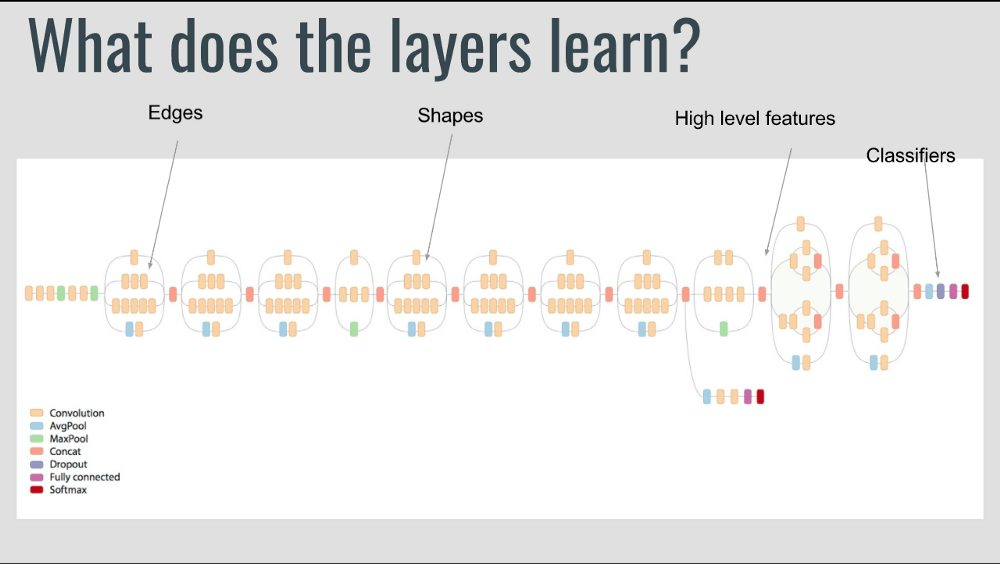

For a small dataset, a pretrained encoder can be paired with a decoder. Reusing pretrained layers may improve convergence, but the benefit must be measured. A related example is [TernausNet](https://arxiv.org/abs/1801.05746), which uses a U-Net architecture with a VGG11-based encoder.

The historical experiment compares models using *segmentation-models*, a Python library for image segmentation with Keras/TensorFlow. At the time, the notebook described a high-level model API, four segmentation architectures, 25 backbone options and pretrained weights. These are historical package descriptions rather than current compatibility claims.

In [ ]:
#!pip install segmentation-models

In [ ]:
from segmentation_models import Unet, Linknet, PSPNet, FPN
from segmentation_models.backbones import get_preprocessing
from segmentation_models.losses import bce_jaccard_loss
from segmentation_models.metrics import iou_score

U-Net with a pretrained `resnet34` encoder.

In [ ]:
train_x, test_x, train_y, test_y = train_test_split(train_2_5, thresh1, test_size=1/8.2, random_state=3017)

model_unet = Unet(backbone_name='resnet34', input_shape=(32, 32, 3), encoder_weights='imagenet', freeze_encoder=True)
model_unet.compile('Adam', loss=bce_jaccard_loss, metrics=[mean_iou, iou_score, mse])

tensorboard = TensorBoard(log_dir='logs/{}'.format(time()))
earlystopper = EarlyStopping(patience=5, verbose=1)
checkpointer = ModelCheckpoint('model_unet.h5', verbose=1, save_best_only=True)

# Train the model
results = model_unet.fit(
    x=train_x,
    y=train_y,
    batch_size=16,
    epochs=100,
    validation_split=0.1,
    callbacks=[earlystopper, checkpointer, tensorboard]
)

In [ ]:
print('Test-set metrics', model_unet.evaluate(test_x, test_y))

print(results.history.keys())
# Plot the metric history
plt.plot(results.history['mean_iou'])
plt.plot(results.history['val_mean_iou'])
plt.title('model_unet mean_iou')
plt.ylabel('IoU')
plt.xlabel('epoch')
plt.legend(['mean_iou', 'val_mean_iou'], loc='upper left')
plt.show()

# Plot the Jaccard-score history
plt.plot(results.history['iou_score'])
plt.plot(results.history['val_iou_score'])
plt.title('model_unet iou_score')
plt.ylabel('iou_score')
plt.xlabel('epoch')
plt.legend(['iou_score', 'val_iou_score'], loc='upper left')
plt.show()

# Plot the mean-squared-error history
plt.plot(results.history['mse'])
plt.plot(results.history['val_mse'])
plt.title('model_unet mse')
plt.ylabel('mse')
plt.xlabel('epoch')
plt.legend(['mse', 'val_mse'], loc='upper left')
plt.show()

# Plot the loss history
plt.plot(results.history['loss'])
plt.plot(results.history['val_loss'])
plt.title('model_unet loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()

In [ ]:
# Predictions on training, validation and test data
#model1 = load_model('model_segm.h5', custom_objects={'mean_iou': mean_iou, 'iou': iou})
preds_test = model_unet.predict(test_x, verbose=1)

# # Threshold the predictions
# preds_test_t = (preds_test > 1).astype(np.uint8)

# Inspect a randomly selected example
ix = random.randint(0, len(preds_test)-1)
print(ix)
py.imshow(np.squeeze(test_y[ix]))
plt.show()
py.imshow(np.squeeze(preds_test[ix]))
plt.show()

LinkNet with a pretrained `resnet34` encoder.

In [ ]:
train_x, test_x, train_y, test_y = train_test_split(train_2_5, thresh1, test_size=1/8.2, random_state=3017)

model_linknet = Linknet(backbone_name='resnet34', input_shape=(32, 32, 3), encoder_weights='imagenet', freeze_encoder=True)
model_linknet.compile('Adam', loss=bce_jaccard_loss, metrics=[mean_iou, iou_score, mse])

tensorboard = TensorBoard(log_dir='logs/{}'.format(time()))
earlystopper = EarlyStopping(patience=5, verbose=1)
checkpointer = ModelCheckpoint('model_linknet.h5', verbose=1, save_best_only=True)

# Train the model
results = model_linknet.fit(
    x=train_x,
    y=train_y,
    batch_size=16,
    epochs=100,
    validation_split=0.1,
    callbacks=[earlystopper, checkpointer, tensorboard]
)

In [ ]:
print('Test-set metrics', model_linknet.evaluate(test_x, test_y))

print(results.history.keys())
# Plot the metric history
plt.plot(results.history['mean_iou'])
plt.plot(results.history['val_mean_iou'])
plt.title('model_Linknet mean_iou')
plt.ylabel('IoU')
plt.xlabel('epoch')
plt.legend(['mean_iou', 'val_mean_iou'], loc='upper left')
plt.show()

# Plot the Jaccard-score history
plt.plot(results.history['iou_score'])
plt.plot(results.history['val_iou_score'])
plt.title('model_Linknet iou_score')
plt.ylabel('iou_score')
plt.xlabel('epoch')
plt.legend(['iou_score', 'val_iou_score'], loc='upper left')
plt.show()

# Plot the mean-squared-error history
plt.plot(results.history['mse'])
plt.plot(results.history['val_mse'])
plt.title('model_Linknet mse')
plt.ylabel('mse')
plt.xlabel('epoch')
plt.legend(['mse', 'val_mse'], loc='upper left')
plt.show()

# Plot the loss history
plt.plot(results.history['loss'])
plt.plot(results.history['val_loss'])
plt.title('model_Linknet loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['loss', 'val_loss'], loc='upper left')
plt.show()

In [ ]:
# Predictions on training, validation and test data
#model1 = load_model('model_segm.h5', custom_objects={'mean_iou': mean_iou, 'iou': iou})
preds_test = model_linknet.predict(test_x, verbose=1)

# # Threshold the predictions
# preds_test_t = (preds_test > 1).astype(np.uint8)

# Inspect a randomly selected example
ix = random.randint(0, len(preds_test)-1)
print(ix)
py.imshow(np.squeeze(test_x[ix]), cmap='Blues')
plt.show()
py.imshow(np.squeeze(test_y[ix]), cmap='Blues')
plt.show()
py.imshow(np.squeeze(preds_test[ix]), cmap='Blues')
plt.show()